# Project 1: Sentiment classification on IMDB

**Goal:** predict whether a movie review is **positive** or **negative**.

**Dataset:** [IMDB](https://huggingface.co/datasets/mteb/imdb) (Large Movie Review Dataset) from Hugging Face.

The notebook follows the 6 steps of the *Get to work!* section in `project.ipynb`:

| Step | Section |
|---|---|
| 1 | Dataset & statistics |
| 2 | Tokenizer |
| 3 | Features |
| 4 | Architectures |
| 5 | Evaluation |
| 6 | Analysis |


## Setup

In [23]:
%load_ext autoreload
%autoreload 2

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

# make the course package `part1` importable
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import part1

import re
import numpy as np
from collections import Counter, OrderedDict   # OrderedDict: used in the tutorial's experiment code

# folder for everything this project saves (kept apart from the tutorial's results)
results_folder = Path("./results_project")
results_folder.mkdir(parents=True, exist_ok=True)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1. Dataset & statistics

First we load the data and look at it: how many reviews are there, how are the labels divided, and how long are the reviews?

In [24]:
from datasets import load_dataset

dataset = load_dataset("mteb/imdb")
print(dataset)

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'label_text'],
        num_rows: 24904
    })
    test: Dataset({
        features: ['text', 'label', 'label_text'],
        num_rows: 24678
    })
})


In [25]:
# one example review and its label
print(dataset["train"]["text"][0])
print("\nlabel:", dataset["train"]["label"][0], "=", dataset["train"]["label_text"][0])

I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and ordinary denizens of Stockholm about their opinions on politics, she has sex with her drama teacher, classmates, and married men.<br /><br />What kills me about I AM CURIOUS-YELLOW is that 40 years ago, this was considered pornographic. Really, the sex and nudity scenes are few and far between, eve

In [26]:
# number of reviews per label
print("train:", Counter(dataset["train"]["label_text"]))
print("test: ", Counter(dataset["test"]["label_text"]))

train: Counter({'positive': 12472, 'negative': 12432})
test:  Counter({'positive': 12412, 'negative': 12266})


In [27]:
# length of the reviews (in words)
lengths = [len(text.split()) for text in dataset["train"]["text"]]
print("average:", round(np.mean(lengths)), "words")
print("median: ", round(np.median(lengths)), "words")
print("shortest:", min(lengths), "| longest:", max(lengths))

# how many reviews contain the HTML line break <br />?
print("\nreviews with <br />:", sum("<br" in text for text in dataset["train"]["text"]), "of", len(lengths))

average: 234 words
median:  174 words
shortest: 10 | longest: 2470

reviews with <br />: 14615 of 24904


**What we see**
- About **25,000 training** and **25,000 test** reviews.
- **2 classes**, almost exactly **50/50**. So **accuracy** is a fair metric: a model that always guesses one class would only get 50%.
- Reviews are **long**: 234 words on average (AG News articles in the tutorial were much shorter).
- More than half of the reviews contain the HTML code `<br />`. It says nothing about sentiment, so we remove it.

### Cleaning and splitting the data

- **Cleaning:** replace every `<br />` with a space.
- **Cross-validation:** split the training data into **5 folds**. Each time, a model trains on 4 folds and is checked on the 5th. Doing this 5 times gives a more reliable result than one single split.
- **Test set:** kept apart and only used at the very end, so the final score is measured on reviews the model has never seen.

In [28]:
def clean(text):
    """Replace the HTML line break <br /> with a space."""
    return re.sub(r"<br\s*/?>", " ", text)

# (review, label) pairs; label 0 = negative, 1 = positive
train_pairs = [(clean(text), label) for text, label in zip(dataset["train"]["text"], dataset["train"]["label"])]
test_pairs  = [(clean(text), label) for text, label in zip(dataset["test"]["text"],  dataset["test"]["label"])]   # only for the very end!

imdb_outcome_space = part1.clslib.NamedClasses(['negative', 'positive'])
print(imdb_outcome_space)

0: negative, 1: positive


In [29]:
my_seeds = [0]     # one run of cross-validation (more seeds, e.g. [0, 3, 5], give more runs)
num_folds = 5

my_cross_validation_sets = []
for seed in my_seeds:
    my_cross_validation_sets.append(
        part1.experiment.cross_validation_split(pairs=train_pairs, k=num_folds, seed=seed)
    )

fold = my_cross_validation_sets[0][0]
print(len(fold["training"]), "training reviews and", len(fold["validation"]), "validation reviews per fold")

19923 training reviews and 4981 validation reviews per fold


## 2. Tokenizer

A tokenizer cuts a review into pieces (*tokens*). Like in the tutorial, we use **BPE**: frequent words stay whole, and rare or unknown words are built from smaller known pieces.

**Our choices**

| Question (from *Get to work!*) | Our choice | Why |
|---|---|---|
| Use the tutorial's tokenizer? | No, we train a **new** one | The tutorial tokenizer was trained on news; movie reviews use different words. |
| Which data to train it on? | The IMDB **training** texts | Never the test set, so no information from the test set leaks into the model. |
| Is our dataset big enough? | Yes | ~25,000 reviews × ~234 words ≈ 5.8 million words, so no extra data is needed. |
| Which hyperparameters? | `vocab_size = 5000`, `min_frequency = 2` | See the comparison below. |

In [30]:
corpus = [text for text, label in train_pairs]   # training texts only

vocab_size = 5000      # number of different tokens
min_frequency = 2      # only merge pairs that occur at least twice
tokenizer = part1.experiment.train_tokenizer(corpus, vocab_size, min_frequency)
tokenizer.save(f"{results_folder}/BPE_imdb_vs_{vocab_size}_mf_{min_frequency}.json")

print(tokenizer.encode("This movie was not bad at all!").tokens)

['▁This', '▁movie', '▁was', '▁not', '▁bad', '▁at', '▁all', '!']


### Comparison: why this tokenizer?

We compare 4 BPE tokenizers on the same 2,000 reviews:
- **AG News, 1000**: the tokenizer from the tutorial
- **IMDB, 1000 / 5000 / 10000**: trained on our reviews, with different vocabulary sizes

We look at two things:
1. **Tokens per review**: fewer tokens means more words stay whole, and whole words carry more meaning than pieces.
2. **How sentiment words are cut**, e.g. *boring* or *masterpiece*.

No model is trained here, so this only takes about 10 seconds.

In [31]:
ag_news_texts = part1.experiment.download_ag_news_texts()

tokenizers_to_compare = {
    "AG News, 1000 (tutorial)": part1.experiment.train_tokenizer(ag_news_texts, 1000, 2),
    "IMDB, 1000":               part1.experiment.train_tokenizer(corpus, 1000, 2),
    "IMDB, 5000 (our choice)":  tokenizer,   # trained above
    "IMDB, 10000":              part1.experiment.train_tokenizer(corpus, 10000, 2),
}

In [32]:
# 1. tokens per review (on 2,000 validation reviews of fold 0)
sample = [text for text, label in fold["validation"]][:2000]
words_in_sample = sum(len(text.split()) for text in sample)

print(f"{'tokenizer':26} {'tokens per review':>18} {'tokens per word':>16}")
for name, tok in tokenizers_to_compare.items():
    n_tokens = sum(len(tok.encode(text).ids) for text in sample)
    print(f"{name:26} {n_tokens / len(sample):>18.0f} {n_tokens / words_in_sample:>16.2f}")

tokenizer                   tokens per review  tokens per word
AG News, 1000 (tutorial)                  547             2.32
IMDB, 1000                                482             2.04
IMDB, 5000 (our choice)                   343             1.45
IMDB, 10000                               309             1.31


In [33]:
# 2. how are sentiment words cut into pieces?
sentiment_words = ["disappointing", "masterpiece", "boring", "awful", "brilliant", "overrated"]

for name, tok in tokenizers_to_compare.items():
    print(name)
    for word in sentiment_words:
        print(f"   {word:14} -> {tok.encode(word).tokens}")

AG News, 1000 (tutorial)
   disappointing  -> ['▁dis', 'app', 'oin', 'ting']
   masterpiece    -> ['▁m', 'as', 'ter', 'p', 'i', 'ec', 'e']
   boring         -> ['▁b', 'or', 'ing']
   awful          -> ['▁a', 'w', 'f', 'ul']
   brilliant      -> ['▁b', 'r', 'ill', 'ian', 't']
   overrated      -> ['▁over', 'r', 'ated']
IMDB, 1000
   disappointing  -> ['▁dis', 'app', 'o', 'int', 'ing']
   masterpiece    -> ['▁m', 'as', 'ter', 'p', 'ie', 'ce']
   boring         -> ['▁b', 'or', 'ing']
   awful          -> ['▁aw', 'ful']
   brilliant      -> ['▁b', 'rill', 'i', 'ant']
   overrated      -> ['▁over', 'r', 'ated']
IMDB, 5000 (our choice)
   disappointing  -> ['▁disappoint', 'ing']
   masterpiece    -> ['▁masterpiece']
   boring         -> ['▁boring']
   awful          -> ['▁awful']
   brilliant      -> ['▁brilliant']
   overrated      -> ['▁over', 'rated']
IMDB, 10000
   disappointing  -> ['▁disappointing']
   masterpiece    -> ['▁masterpiece']
   boring         -> ['▁boring']
   awful        

**Result**

| Tokenizer | Tokens per review | *masterpiece* becomes |
|---|---|---|
| AG News, 1000 (tutorial) | 547 | `m, as, ter, p, i, ec, e` |
| IMDB, 1000 | 482 | `m, as, ter, p, ie, ce` |
| **IMDB, 5000 (our choice)** | **343** | **`masterpiece`** |
| IMDB, 10000 | 309 | `masterpiece` |

**Conclusion**
- **Own tokenizer instead of the tutorial's:** the news tokenizer cuts movie words into meaningless pieces. Trained on IMDB, the tokenizer fits our data better.
- **5000 instead of 1000:** about 30% fewer tokens per review, and sentiment words like *boring*, *awful* and *brilliant* stay whole.
- **5000 instead of 10000:** 10000 only gives about 10% fewer tokens, but every review vector becomes twice as big (slower training, more memory).

So **5000** is a good balance.

*Limitation:* we compared the tokenizers themselves, not the accuracy of a classifier trained with each of them.

## 3. Features

A model can only work with numbers. An **encoder** turns a review into a list of 5,000 numbers: one number per token in the vocabulary.

| Encoder | Number for each token | "great great movie" |
|---|---|---|
| `TokenIndicator` | Does the token appear? (1 or 0) | great = 1, movie = 1 |
| `BagOfWords` | How often does it appear? | great = 2, movie = 1 |

Both **forget the word order**: "not good" and "good, not" get the same numbers.

*Note on `TokenIndicator`:* the course package (`part1/clslib.py`) already has one, but on one line it uses the global variable `tokenizer` instead of its own `self.tokenizer`, so it can pick the wrong tokenizer. We therefore define it here ourselves, with that line fixed.

In [34]:
class TokenIndicator(part1.clslib.Encoder):
    """1 if a token appears in the review, 0 if not."""

    def __init__(self, tokenizer):
        self.tokenizer = tokenizer                      # remember which tokenizer to use

    def __len__(self):
        return len(self.tokenizer.get_vocab())          # number of dimensions = vocabulary size

    def __call__(self, x):
        token_ids = set(self.tokenizer.encode(x).ids)   # the tokens in the review, each only once
        vector = np.zeros(len(self), dtype=np.float32)  # start with all zeros
        vector[list(token_ids)] = 1                     # 1 for every token that appears
        return vector

In [35]:
class BagOfWords(part1.clslib.Encoder):
    """How many times each token appears in the review."""

    def __init__(self, tokenizer):
        self.tokenizer = tokenizer                      # remember which tokenizer to use

    def __len__(self):
        return len(self.tokenizer.get_vocab())          # number of dimensions = vocabulary size

    def __call__(self, x):
        token_ids = self.tokenizer.encode(x).ids        # the tokens in the review, with repeats
        counts = np.bincount(token_ids, minlength=len(self))   # count how often each token appears
        return counts.astype(np.float32)

*Why `float32`?* With 5,000 numbers per review and ~20,000 training reviews, `float32` uses half the memory of the default `float64`, with the same results.

**Check:** do both encoders do what we expect?

In [36]:
token_indicator_encoder = TokenIndicator(tokenizer)
bow_encoder = BagOfWords(tokenizer)

example = "great great movie"
print("tokens:", tokenizer.encode(example).tokens, "\n")
for token in dict.fromkeys(tokenizer.encode(example).tokens):   # each token once
    i = tokenizer.token_to_id(token)
    print(f"{token:8}  TokenIndicator = {token_indicator_encoder(example)[i]:.0f}   BagOfWords = {bow_encoder(example)[i]:.0f}")

tokens: ['▁great', '▁great', '▁movie'] 

▁great    TokenIndicator = 1   BagOfWords = 2
▁movie    TokenIndicator = 1   BagOfWords = 1


In [37]:
# the same on a real review
review = train_pairs[0][0]
indicators = token_indicator_encoder(review)
counts = bow_encoder(review)

print("numbers per review (dimensions):", len(indicators))
print("tokens in this review:          ", int(counts.sum()))
print("different tokens in this review:", int(indicators.sum()))
print("most frequent token:            ", tokenizer.id_to_token(int(counts.argmax())), f"({int(counts.max())} times)")

numbers per review (dimensions): 5000
tokens in this review:           409
different tokens in this review: 252
most frequent token:             ▁the (9 times)


**What we see**
- A review uses only a few hundred of the 5,000 tokens, so most numbers in the vector are 0.
- IMDB reviews are long, so many tokens appear more than once. Bag-of-words keeps that information, token indicators throw it away. That is why we expect bag-of-words to work a bit better on IMDB than it did on AG News.

### Our own representation: bag-of-bigrams

**The problem:** token indicators and bag-of-words forget the word order. "not bad" and "bad, not" look the same, and the model only sees *not* and *bad* separately. For sentiment that matters: "not bad" is positive, "bad" is negative.

**Our idea:** also count **bigrams**: pairs of tokens that stand next to each other, like *(not, bad)* or *(waste, of)*. A bigram keeps a little bit of word order.

**How it works**
- The vector = **bag-of-words** (5,000 numbers, as before) **+ bigram counts** (20,000 numbers) = **25,000 numbers** per review.
- We only keep the **20,000 most frequent bigrams** in the training texts. There are over 1 million different bigrams, and almost all of them are too rare to learn anything from.
- Like the tokenizer, the bigram list is made from the training texts only.

In [38]:
class BagOfBigrams(part1.clslib.Encoder):
    """Bag-of-words counts + counts of the most frequent bigrams (pairs of neighbouring tokens)."""

    def __init__(self, tokenizer, corpus, num_bigrams=20000):
        self.tokenizer = tokenizer
        self.vocab_size = len(tokenizer.get_vocab())

        # count every pair of neighbouring tokens in the training texts
        bigram_counts = Counter()
        for encoding in tokenizer.encode_batch(corpus):
            ids = encoding.ids
            bigram_counts.update(zip(ids, ids[1:]))

        # keep the most frequent ones; each gets its own position in the vector
        most_frequent = bigram_counts.most_common(num_bigrams)
        self.bigram_to_index = {bigram: i for i, (bigram, count) in enumerate(most_frequent)}

    def __len__(self):
        return self.vocab_size + len(self.bigram_to_index)       # 5,000 + 20,000

    def __call__(self, x):
        token_ids = self.tokenizer.encode(x).ids
        vector = np.zeros(len(self), dtype=np.float32)

        # part 1: bag-of-words (how often each token appears)
        vector[:self.vocab_size] = np.bincount(token_ids, minlength=self.vocab_size)

        # part 2: how often each known bigram appears
        for bigram in zip(token_ids, token_ids[1:]):
            i = self.bigram_to_index.get(bigram)
            if i is not None:                                      # skip bigrams that are too rare
                vector[self.vocab_size + i] += 1
        return vector

In [39]:
bigram_encoder = BagOfBigrams(tokenizer, corpus, num_bigrams=20000)   # takes about 5 seconds
print("numbers per review:", len(bigram_encoder))

def bigram_name(bigram):
    return " + ".join(tokenizer.id_to_token(i) for i in bigram)

print("\nmost frequent bigrams:")
for bigram in list(bigram_encoder.bigram_to_index)[:5]:
    print("  ", bigram_name(bigram))

numbers per review: 25000

most frequent bigrams:
   ▁of + ▁the
   ▁in + ▁the
   . + ▁
   ▁is + ▁a
   ▁and + ▁the


In [40]:
# which bigrams does the encoder find in a short review?
example = "This movie was not bad at all, a waste of time it was not."
token_ids = tokenizer.encode(example).ids
print("tokens:", tokenizer.encode(example).tokens, "\n")

for bigram in zip(token_ids, token_ids[1:]):
    known = bigram in bigram_encoder.bigram_to_index
    print(f"{bigram_name(bigram):22} {'counted' if known else 'too rare, skipped'}")

tokens: ['▁This', '▁movie', '▁was', '▁not', '▁bad', '▁at', '▁all,', '▁a', '▁waste', '▁of', '▁time', '▁it', '▁was', '▁not.'] 

▁This + ▁movie         counted
▁movie + ▁was          counted
▁was + ▁not            counted
▁not + ▁bad            counted
▁bad + ▁at             too rare, skipped
▁at + ▁all,            counted
▁all, + ▁a             counted
▁a + ▁waste            counted
▁waste + ▁of           counted
▁of + ▁time            counted
▁time + ▁it            counted
▁it + ▁was             counted
▁was + ▁not.           too rare, skipped


**What we see**
- The most frequent bigrams are mostly small grammar words (*of + the*, *in + the*). They say little about sentiment, but they are cheap to keep.
- Useful sentiment bigrams such as *not + bad* and *waste + of* are in the list, so the model can now learn that "not bad" is different from "bad".
- **Downside:** vectors are 5× bigger than bag-of-words (25,000 instead of 5,000 numbers), so training uses more memory and time.
- Whether bigrams really give a better accuracy is tested with cross-validation in section 4/5.

## 4. Architectures

We train two models from the course code, both on exactly the same 5 folds:

| Model | What it does | Course code |
|---|---|---|
| **Log-linear** (logistic regression) | Gives every feature one weight, adds them up and turns the sum into a probability. | `part1/loglin.py` |
| **MLP** | Puts a hidden layer of 128 units between input and output, so it can combine features. | `part1/smlp.py` (`SparseMLP`) |

**Plan**
1. Log-linear on all 3 representations: token indicators, bag-of-words, bag-of-bigrams.
2. MLP only on the representation that works best with log-linear (an MLP is much slower to train).
3. Our own architecture (section 4.3).

In [41]:
"""
Every model writes its 5 fold accuracies to `results_project/results.json`, e.g. `{"loglin_bow": [0.87, ...], ...}`. 
New results are added to what is already in the file, so nothing gets overwritten.
"""

import json
import time

results_file = results_folder / "results.json"

def save_results(new_results):
    """Add {model name: [5 fold accuracies]} to results.json, keeping what is already in there."""
    results = json.loads(results_file.read_text()) if results_file.exists() else {}
    results.update({name: [float(acc) for acc in accs] for name, accs in new_results.items()})
    results_file.write_text(json.dumps(results, indent=2))
    print("saved to", results_file, "| models in file:", list(results))

### 4.1 Log-linear Architecture

We use the course code: `part1.experiment.cross_validation_experiment` with `model_option="logistic"`. For each fold it trains `LogisticRegression(solver="saga")` with `part1.loglin.fit` (at most 100 training runs, `max_iter=100`) and predicts with `part1.loglin.predict`. The models are saved in `results_project/loglin_<representation>/`.

We also record whether it **converged**: did it stop because the weights stopped changing, or because it ran out of runs? A model that did not converge might do better with more runs.

In [42]:
from sklearn.exceptions import ConvergenceWarning
warnings.simplefilter("ignore", ConvergenceWarning)    # we record convergence ourselves, below

encoders = {
    "indicator": token_indicator_encoder,
    "bow":       bow_encoder,
    "bigram":    bigram_encoder,
}

loglin_results = {}
for name, encoder in encoders.items():
    start = time.time()
    run = part1.experiment.cross_validation_experiment(     # course code: part1.loglin.fit and .predict
        data_splits=my_cross_validation_sets[0],            # the same 5 folds as everywhere
        outcome_space=imdb_outcome_space,
        encoder=encoder,
        model_option="logistic",
        save_to=f"{results_folder}/loglin_{name}/seed-0",
        loglin_args={"max_iter": 100},
    )
    accuracies = list(run["accuracies"].values())

    # did it converge? n_iter_ == max_iter means it ran out of runs
    converged = [bool(part1.loglin.load(model_path).n_iter_.max() < 100) for model_path in run["models"].values()]

    loglin_results[name] = {"accuracies": accuracies, "converged": converged}
    print(f"{name:10} mean accuracy: {np.mean(accuracies):.4f} | converged in {sum(converged)}/{num_folds} folds "
          f"| time: {time.time() - start:.0f} s")

save_results({f"loglin_{name}": result["accuracies"] for name, result in loglin_results.items()})

  0%|          | 0/5 [00:00<?, ?it/s]

indicator  mean accuracy: 0.8558 | converged in 0/5 folds | time: 183 s


  0%|          | 0/5 [00:00<?, ?it/s]

bow        mean accuracy: 0.8611 | converged in 0/5 folds | time: 188 s


  0%|          | 0/5 [00:00<?, ?it/s]

bigram     mean accuracy: 0.8696 | converged in 0/5 folds | time: 113 s
saved to results_project\results.json | models in file: ['loglin_indicator', 'loglin_bow', 'loglin_bigram']


**What we see**

| Representation | Mean accuracy | Converged |
|---|---|---|
| Token indicators | 0.856 | 0 of 5 folds |
| Bag-of-words | 0.861 | 0 of 5 folds |
| **Bag-of-bigrams** | **0.870** | 0 of 5 folds |

- **Counting helps:** bag-of-words beats token indicators in all 5 folds. Knowing *how often* a word appears is useful in long reviews.
- **Bigrams help more:** bag-of-bigrams beats bag-of-words in all 5 folds. Word pairs like *not + bad* add information that single tokens miss.
- **No fold converged** within 100 runs, for any representation. The features are raw counts, and the `saga` solver learns slowly on unscaled numbers. With more runs the accuracies might go up a little. We keep `max_iter=100`, the same as the course code, so all three representations get the same treatment.
- The course code encodes all reviews again for every fold, so this cell takes about 8 minutes (2 to 3 minutes per representation).

### 4.2 MLP

Again the course code: `part1.experiment.cross_validation_experiment` with `model_option="mlp"`. For each fold it trains `SparseMLP` from `part1/smlp.py` with `part1.smlp.train_neural_network_model`.

The settings are the same as in the tutorial: a hidden layer of 128 units, dropout 0.1, learning rate 1e-4, weight decay 1e-4, batches of 64 reviews, 10 epochs. After each epoch it looks at the validation loss. The accuracy of a fold is the one from the epoch with the **lowest validation loss**.

We train it only on the best representation from 4.1.

In [43]:
import torch

best_representation = max(loglin_results, key=lambda name: np.mean(loglin_results[name]["accuracies"]))
print("best representation with log-linear:", best_representation)

mlp_name = f"mlp_{best_representation}"
mlp_args = {             # as in the tutorial
    "hidden_dim": 128,
    "dropout": 0.1,
    "batch_size": 64,
    "learning_rate": 1e-4,
    "weight_decay": 1e-4,
    "num_epochs": 10,
}

best representation with log-linear: bigram


First we time **one fold**, to know how long all 5 will take.

In [44]:
torch.manual_seed(0)     # same start weights and batch order every time we run the notebook

start = time.time()
mlp_fold_0 = part1.experiment.cross_validation_experiment(
    data_splits={0: my_cross_validation_sets[0][0]},       # only fold 0
    outcome_space=imdb_outcome_space,
    encoder=encoders[best_representation],
    model_option="mlp",
    save_to=f"{results_folder}/{mlp_name}/seed-0",
    smlp_args=mlp_args,
)
seconds = time.time() - start

print(f"\nfold 0 accuracy: {mlp_fold_0['accuracies'][0]:.4f}")
print(f"time: {seconds:.0f} s, so the other 4 folds take about {4 * seconds / 60:.0f} minutes")

  0%|          | 0/1 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 15.633 seconds
Dataloader done! Time taken: 2.879 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

c:\Users\VOS-User\OneDrive - UvA\Documents\GitHub\NLP1\nlp1-student-tutorial1-2026\part1\smlp.py:68: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_new.cpp:252.)
  indices = torch.tensor([x.row, x.col], dtype=torch.long)
c:\Users\VOS-User\OneDrive - UvA\Documents\GitHub\NLP1\nlp1-student-tutorial1-2026\part1\smlp.py:71: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:923.)
  return torch.s

Epoch 01 | train loss: 0.4440 | train acc: 0.8263 | val loss: 0.3175 | val acc: 0.8886
Epoch 02 | train loss: 0.2237 | train acc: 0.9284 | val loss: 0.2687 | val acc: 0.9024
Epoch 03 | train loss: 0.1458 | train acc: 0.9578 | val loss: 0.2645 | val acc: 0.9032
Epoch 04 | train loss: 0.0992 | train acc: 0.9757 | val loss: 0.2760 | val acc: 0.8980
Epoch 05 | train loss: 0.0680 | train acc: 0.9872 | val loss: 0.2901 | val acc: 0.8960
Epoch 06 | train loss: 0.0474 | train acc: 0.9934 | val loss: 0.3128 | val acc: 0.8954
Epoch 07 | train loss: 0.0326 | train acc: 0.9975 | val loss: 0.3347 | val acc: 0.8930
Epoch 08 | train loss: 0.0228 | train acc: 0.9988 | val loss: 0.3589 | val acc: 0.8950
Epoch 09 | train loss: 0.0168 | train acc: 0.9994 | val loss: 0.3807 | val acc: 0.8924
Epoch 10 | train loss: 0.0125 | train acc: 0.9996 | val loss: 0.4038 | val acc: 0.8922
Training done! Time taken: 112.689 seconds

fold 0 accuracy: 0.9032
time: 133 s, so the other 4 folds take about 9 minutes


In [45]:
# the other 4 folds
mlp_other_folds = part1.experiment.cross_validation_experiment(
    data_splits={fold: my_cross_validation_sets[0][fold] for fold in range(1, num_folds)},
    outcome_space=imdb_outcome_space,
    encoder=encoders[best_representation],
    model_option="mlp",
    save_to=f"{results_folder}/{mlp_name}/seed-0",
    smlp_args=mlp_args,
)

mlp_accuracies = [mlp_fold_0["accuracies"][0]] + [mlp_other_folds["accuracies"][fold] for fold in range(1, num_folds)]
print(f"\n{mlp_name}: mean accuracy {np.mean(mlp_accuracies):.4f}")
save_results({mlp_name: mlp_accuracies})

  0%|          | 0/4 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 16.176 seconds
Dataloader done! Time taken: 2.984 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.4452 | train acc: 0.8300 | val loss: 0.3160 | val acc: 0.8848
Epoch 02 | train loss: 0.2229 | train acc: 0.9293 | val loss: 0.2668 | val acc: 0.8986
Epoch 03 | train loss: 0.1442 | train acc: 0.9588 | val loss: 0.2653 | val acc: 0.8950
Epoch 04 | train loss: 0.0977 | train acc: 0.9770 | val loss: 0.2797 | val acc: 0.8920
Epoch 05 | train loss: 0.0667 | train acc: 0.9880 | val loss: 0.2941 | val acc: 0.8932
Epoch 06 | train loss: 0.0462 | train acc: 0.9939 | val loss: 0.3167 | val acc: 0.8928
Epoch 07 | train loss: 0.0322 | train acc: 0.9970 | val loss: 0.3387 | val acc: 0.8910
Epoch 08 | train loss: 0.0228 | train acc: 0.9990 | val loss: 0.3648 | val acc: 0.8890
Epoch 09 | train loss: 0.0163 | train acc: 0.9996 | val loss: 0.3859 | val acc: 0.8896
Epoch 10 | train loss: 0.0119 | train acc: 0.9998 | val loss: 0.4116 | val acc: 0.8868
Training done! Time taken: 105.560 seconds
Transforming documents...
Document transformation done! Time taken: 15.377 seconds
Data

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.4433 | train acc: 0.8307 | val loss: 0.3085 | val acc: 0.8918
Epoch 02 | train loss: 0.2191 | train acc: 0.9318 | val loss: 0.2721 | val acc: 0.8954
Epoch 03 | train loss: 0.1433 | train acc: 0.9582 | val loss: 0.2750 | val acc: 0.8954
Epoch 04 | train loss: 0.0969 | train acc: 0.9770 | val loss: 0.2806 | val acc: 0.8984
Epoch 05 | train loss: 0.0659 | train acc: 0.9883 | val loss: 0.3000 | val acc: 0.8964
Epoch 06 | train loss: 0.0455 | train acc: 0.9947 | val loss: 0.3202 | val acc: 0.8954
Epoch 07 | train loss: 0.0316 | train acc: 0.9977 | val loss: 0.3417 | val acc: 0.8940
Epoch 08 | train loss: 0.0222 | train acc: 0.9990 | val loss: 0.3658 | val acc: 0.8908
Epoch 09 | train loss: 0.0163 | train acc: 0.9994 | val loss: 0.3873 | val acc: 0.8908
Epoch 10 | train loss: 0.0120 | train acc: 0.9995 | val loss: 0.4093 | val acc: 0.8912
Training done! Time taken: 103.743 seconds
Transforming documents...
Document transformation done! Time taken: 15.391 seconds
Data

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.4500 | train acc: 0.8304 | val loss: 0.3056 | val acc: 0.8898
Epoch 02 | train loss: 0.2253 | train acc: 0.9273 | val loss: 0.2645 | val acc: 0.8958
Epoch 03 | train loss: 0.1460 | train acc: 0.9574 | val loss: 0.2593 | val acc: 0.8954
Epoch 04 | train loss: 0.0980 | train acc: 0.9774 | val loss: 0.2768 | val acc: 0.8950
Epoch 05 | train loss: 0.0673 | train acc: 0.9883 | val loss: 0.2882 | val acc: 0.8944
Epoch 06 | train loss: 0.0454 | train acc: 0.9947 | val loss: 0.3117 | val acc: 0.8910
Epoch 07 | train loss: 0.0321 | train acc: 0.9969 | val loss: 0.3339 | val acc: 0.8916
Epoch 08 | train loss: 0.0226 | train acc: 0.9990 | val loss: 0.3508 | val acc: 0.8924
Epoch 09 | train loss: 0.0170 | train acc: 0.9992 | val loss: 0.3745 | val acc: 0.8908
Epoch 10 | train loss: 0.0121 | train acc: 0.9998 | val loss: 0.3960 | val acc: 0.8924
Training done! Time taken: 105.849 seconds
Transforming documents...
Document transformation done! Time taken: 15.927 seconds
Data

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.4437 | train acc: 0.8315 | val loss: 0.3144 | val acc: 0.8960
Epoch 02 | train loss: 0.2249 | train acc: 0.9261 | val loss: 0.2794 | val acc: 0.8960
Epoch 03 | train loss: 0.1450 | train acc: 0.9573 | val loss: 0.2740 | val acc: 0.9032
Epoch 04 | train loss: 0.0981 | train acc: 0.9772 | val loss: 0.2806 | val acc: 0.8994
Epoch 05 | train loss: 0.0660 | train acc: 0.9889 | val loss: 0.2963 | val acc: 0.9014
Epoch 06 | train loss: 0.0462 | train acc: 0.9941 | val loss: 0.3180 | val acc: 0.8974
Epoch 07 | train loss: 0.0321 | train acc: 0.9973 | val loss: 0.3370 | val acc: 0.8972
Epoch 08 | train loss: 0.0228 | train acc: 0.9986 | val loss: 0.3599 | val acc: 0.8980
Epoch 09 | train loss: 0.0162 | train acc: 0.9997 | val loss: 0.3809 | val acc: 0.8972
Epoch 10 | train loss: 0.0117 | train acc: 0.9998 | val loss: 0.3993 | val acc: 0.8956
Training done! Time taken: 106.161 seconds

mlp_bigram: mean accuracy 0.8985
saved to results_project\results.json | models in fil

**What we see**
- **The MLP on bigrams reaches 0.899** on average, about 3 points above the log-linear model on the same bigrams (0.870). It is better in all 5 folds.
- **It overfits fast:** after 10 epochs the training accuracy is almost 100%, but the validation loss is lowest at epoch 2 or 3 and rises after that. Picking the epoch with the lowest validation loss protects us against this; fewer epochs would give the same result in less time.
- One fold takes about 2 minutes on a laptop CPU (about 15 seconds to encode the reviews, the rest to train), so all 5 folds take about 10 minutes.

### 4.3 Our own architecture: MLP with 2 hidden layers

The MLP was clearly better than the log-linear model. Does **more depth** help even more? Our own architecture is the MLP from 4.2 with a **second hidden layer** (128 units, again with ReLU and dropout).

- `part1/smlp_new.py`: a copy of `smlp.py` where `SparseMLP` gets the argument `num_hidden_layers`.
- `part1/experiment_new.py`: a copy of `experiment.py` that uses `smlp_new`, so we can train it with the same `cross_validation_experiment`.

Everything else is the same as the MLP in 4.2: bag-of-bigrams, the same 5 folds, the tutorial settings and seed 0. So a difference in accuracy comes from the extra layer.

In [56]:
import part1.experiment_new    # copy of experiment.py that trains smlp_new.SparseMLP (more hidden layers)

own_name = "own_mlp"
torch.manual_seed(0)           # the same seed as the MLP in 4.2

start = time.time()
own_run = part1.experiment_new.cross_validation_experiment(
    data_splits=my_cross_validation_sets[0],           # the same 5 folds
    outcome_space=imdb_outcome_space,
    encoder=encoders[best_representation],             # the same bigrams as the MLP
    model_option="mlp",
    save_to=f"{results_folder}/{own_name}/seed-0",
    smlp_args={**mlp_args, "num_hidden_layers": 2},    # tutorial settings + 1 extra hidden layer
)

own_accuracies = list(own_run["accuracies"].values())
print(f"\n{own_name}: mean accuracy {np.mean(own_accuracies):.4f} | time: {(time.time() - start) / 60:.0f} minutes")
save_results({own_name: own_accuracies})

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 15.185 seconds
Dataloader done! Time taken: 3.138 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.4598 | train acc: 0.8177 | val loss: 0.2998 | val acc: 0.8884
Epoch 02 | train loss: 0.2012 | train acc: 0.9312 | val loss: 0.2718 | val acc: 0.8964
Epoch 03 | train loss: 0.1053 | train acc: 0.9687 | val loss: 0.3156 | val acc: 0.8956
Epoch 04 | train loss: 0.0514 | train acc: 0.9888 | val loss: 0.3689 | val acc: 0.8960
Epoch 05 | train loss: 0.0248 | train acc: 0.9965 | val loss: 0.4616 | val acc: 0.8791
Epoch 06 | train loss: 0.0117 | train acc: 0.9989 | val loss: 0.4746 | val acc: 0.8910
Epoch 07 | train loss: 0.0052 | train acc: 0.9998 | val loss: 0.5170 | val acc: 0.8906
Epoch 08 | train loss: 0.0053 | train acc: 0.9992 | val loss: 0.5674 | val acc: 0.8880
Epoch 09 | train loss: 0.0040 | train acc: 0.9994 | val loss: 0.6008 | val acc: 0.8900
Epoch 10 | train loss: 0.0045 | train acc: 0.9994 | val loss: 0.6258 | val acc: 0.8872
Training done! Time taken: 106.712 seconds
Transforming documents...
Document transformation done! Time taken: 16.093 seconds
Data

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.4647 | train acc: 0.8016 | val loss: 0.2854 | val acc: 0.8938
Epoch 02 | train loss: 0.1974 | train acc: 0.9310 | val loss: 0.2798 | val acc: 0.8946
Epoch 03 | train loss: 0.1014 | train acc: 0.9688 | val loss: 0.3123 | val acc: 0.8926
Epoch 04 | train loss: 0.0515 | train acc: 0.9877 | val loss: 0.3631 | val acc: 0.8900
Epoch 05 | train loss: 0.0222 | train acc: 0.9969 | val loss: 0.4138 | val acc: 0.8904
Epoch 06 | train loss: 0.0128 | train acc: 0.9987 | val loss: 0.5143 | val acc: 0.8882
Epoch 07 | train loss: 0.0076 | train acc: 0.9993 | val loss: 0.5320 | val acc: 0.8832
Epoch 08 | train loss: 0.0058 | train acc: 0.9994 | val loss: 0.5510 | val acc: 0.8850
Epoch 09 | train loss: 0.0047 | train acc: 0.9996 | val loss: 0.6168 | val acc: 0.8830
Epoch 10 | train loss: 0.0055 | train acc: 0.9993 | val loss: 0.6941 | val acc: 0.8797
Training done! Time taken: 109.078 seconds
Transforming documents...
Document transformation done! Time taken: 15.315 seconds
Data

... (2 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.4461 | train acc: 0.8156 | val loss: 0.2806 | val acc: 0.8916
Epoch 02 | train loss: 0.1920 | train acc: 0.9333 | val loss: 0.2935 | val acc: 0.8862
Epoch 03 | train loss: 0.0984 | train acc: 0.9698 | val loss: 0.3029 | val acc: 0.8926
Epoch 04 | train loss: 0.0466 | train acc: 0.9902 | val loss: 0.3658 | val acc: 0.8886
Epoch 05 | train loss: 0.0217 | train acc: 0.9964 | val loss: 0.4268 | val acc: 0.8884
Epoch 06 | train loss: 0.0107 | train acc: 0.9994 | val loss: 0.4737 | val acc: 0.8908
Epoch 07 | train loss: 0.0065 | train acc: 0.9994 | val loss: 0.5544 | val acc: 0.8846
Epoch 08 | train loss: 0.0036 | train acc: 0.9999 | val loss: 0.5711 | val acc: 0.8890
Epoch 09 | train loss: 0.0024 | train acc: 0.9999 | val loss: 0.5832 | val acc: 0.8898
Epoch 10 | train loss: 0.0014 | train acc: 1.0000 | val loss: 0.6298 | val acc: 0.8906
Training done! Time taken: 109.520 seconds
Transforming documents...
Document transformation done! Time taken: 15.436 seconds
Data

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.4522 | train acc: 0.8104 | val loss: 0.2902 | val acc: 0.8920
Epoch 02 | train loss: 0.1944 | train acc: 0.9314 | val loss: 0.2884 | val acc: 0.8960
Epoch 03 | train loss: 0.1000 | train acc: 0.9702 | val loss: 0.3089 | val acc: 0.8986
Epoch 04 | train loss: 0.0523 | train acc: 0.9876 | val loss: 0.3729 | val acc: 0.8926
Epoch 05 | train loss: 0.0251 | train acc: 0.9956 | val loss: 0.4256 | val acc: 0.8900
Epoch 06 | train loss: 0.0133 | train acc: 0.9986 | val loss: 0.4727 | val acc: 0.8922
Epoch 07 | train loss: 0.0100 | train acc: 0.9985 | val loss: 0.5277 | val acc: 0.8876
Epoch 08 | train loss: 0.0066 | train acc: 0.9994 | val loss: 0.5550 | val acc: 0.8878
Epoch 09 | train loss: 0.0031 | train acc: 0.9998 | val loss: 0.5893 | val acc: 0.8884
Epoch 10 | train loss: 0.0069 | train acc: 0.9985 | val loss: 0.6161 | val acc: 0.8865
Training done! Time taken: 109.165 seconds

own_mlp: mean accuracy 0.8941 | time: 11 minutes
saved to results_project\results.json

**What we see**
- **The second hidden layer does not help:** 0.894 on average, against 0.899 for the MLP with one hidden layer (4.2). It is a bit worse in all 5 folds.
- **It overfits even faster:** the validation loss is lowest at epoch 1 or 2 (MLP: 2 or 3). After 10 epochs it is much higher than for the MLP (about 0.63 against 0.40), while the training accuracy reaches almost 100% sooner.
- The extra layer adds only about 16,000 weights to the 3.2 million of the first layer, so training takes about the same time: about 11 minutes for 5 folds.

## 5. Evaluation

All models were tested on the same 5 folds, so we can compare them fold by fold.

In [57]:
import pandas as pd

results = json.loads(results_file.read_text())
table = pd.DataFrame(
    [(name, accuracy, 0, fold) for name, accuracies in results.items() for fold, accuracy in enumerate(accuracies)],
    columns=["model", "accuracy", "run", "fold"],    # the format part1.analysis expects (one run: seed 0)
)

per_fold = table.pivot(index="model", columns="fold", values="accuracy").loc[list(results)]
per_fold.columns = [f"fold {fold}" for fold in per_fold.columns]
per_fold["mean"] = per_fold.mean(axis=1)
per_fold["std"] = per_fold.drop(columns="mean").std(axis=1)
per_fold.round(4)

,fold 0,fold 1,fold 2,fold 3,fold 4,mean,std
model,,,,,,,
loglin_indicator,0.8524,0.8559,0.8518,0.8563,0.8629,0.8558,0.0044
loglin_bow,0.8597,0.8637,0.8546,0.8593,0.8683,0.8611,0.0051
loglin_bigram,0.8665,0.8761,0.8685,0.8633,0.8735,0.8696,0.0052
mlp_bigram,0.9032,0.8950,0.8954,0.8954,0.9032,0.8985,0.0044
own_mlp,0.8964,0.8946,0.8920,0.8916,0.8960,0.8941,0.0022


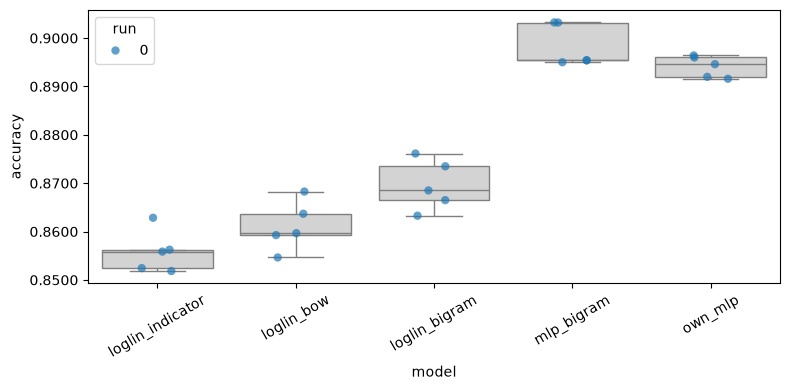

In [58]:
part1.analysis.plot_box_and_points(table)

**What we see**
- The order is the same in every fold: token indicators < bag-of-words < bag-of-bigrams < our MLP with 2 hidden layers < MLP on bigrams.
- The spread between folds is small (std about 0.005). The worst folds of both MLPs (0.895 and 0.892) are still better than the best fold of any log-linear model (0.876).
- The log-linear boxes overlap each other, so those differences are smaller. Section 6 tests whether they are real, with a Bayesian comparison that accounts for the folds sharing training data.

**Is our evaluation adequate?**
- **Accuracy**: fair, because the classes are balanced, so always guessing one class only gets 50%.
- **5-fold cross-validation**: about 5,000 validation reviews per fold, and the spread is small (std about 0.005).
- **Limits**: only one run (seed 0); the folds share training data, so they aren't independent (that's why section 6 uses a Bayesian test); the representation for the MLP was chosen on the same folds; and the test set hasn't been used yet.
- **Other aspects**: training time. We already measured it: about 2–3 minutes per representation for log-linear against about 10 minutes for the MLP. That's a fair trade-off to mention, about +3 points for about 4× the time.

## 6. Analysis

Which design choices are **really** better? The mean accuracies in section 5 are not exact numbers: with another seed for the folds they would change a bit. And the 5 folds share most of their training data, so they are not 5 independent measurements.

Like in the tutorial (*Picking Amongst Design Choices*), we use **Bayesian estimation** with the model of [Benavoli et al. 2017](https://jmlr.org/papers/volume18/16-305/16-305.pdf) (`part1.analysis.BenavoliCorrelatedT`). For two systems A and B, it gives a distribution over the mean difference in accuracy (B − A), and it takes into account that the folds are correlated.

**ROPE** (region of practical equivalence): a difference smaller than the ROPE counts as "practically the same". The analysis then gives three probabilities: *A wins*, *tie* (inside the ROPE) and *B wins*.

**Our ROPE: 0.005** (half an accuracy point), the same as in the tutorial.
- It is about the size of the spread between folds (std 0.004 to 0.005 in section 5). A smaller difference is within the noise of our measurement.
- In one validation fold of 4,981 reviews, 0.005 means about 25 reviews more or less correct.

At the end we check how the conclusions change with a ROPE twice as big (0.01).

In [59]:
rope = 0.005    # as in the tutorial: half an accuracy point

results = json.loads(results_file.read_text())

# like the tutorial's helper: all accuracies of one system (here 1 run x 5 folds)
def get_all_measurements_for(results, sys_name):
    return np.array(results[sys_name])

get_all_measurements_for(results, "loglin_indicator")

array([0.85243927, 0.85585224, 0.85183698, 0.85625376, 0.86285141])

In [60]:
def compare(sys_a, sys_b, rope=rope):
    """The tutorial's comparison cell, for any two systems in results.json."""
    posterior = part1.analysis.BenavoliCorrelatedT(
        get_all_measurements_for(results, sys_a),
        get_all_measurements_for(results, sys_b),
        names=[sys_a, sys_b],
    )
    p_a, p_tie, p_b = posterior.probs(rope)
    print(f"A={sys_a} B={sys_b}: P(A wins)={p_a:.4f} P(Tie)={p_tie:.4f} P(B wins)={p_b:.4f} Effect Size={posterior.effect_size:.2f}")
    _ = posterior.plot(rope)

### 6.1 Representations (log-linear)

Does **counting** tokens help, compared to only marking them? (token indicators vs bag-of-words)

A=loglin_indicator B=loglin_bow: P(A wins)=0.0014 P(Tie)=0.4363 P(B wins)=0.5623 Effect Size=3.38


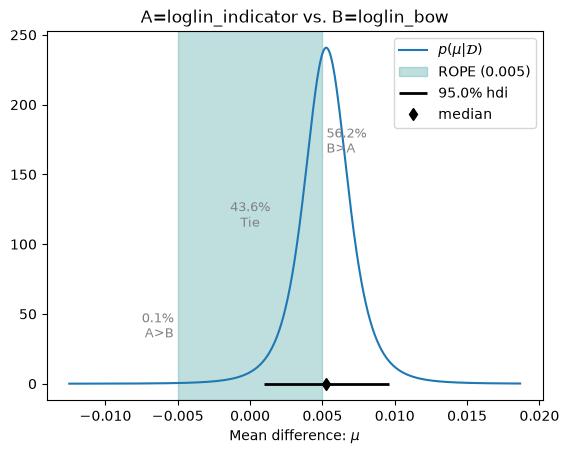

In [61]:
compare("loglin_indicator", "loglin_bow")

Do **bigrams** help, compared to single tokens? (bag-of-words vs bag-of-bigrams)

A=loglin_bow B=loglin_bigram: P(A wins)=0.0052 P(Tie)=0.1477 P(B wins)=0.8471 Effect Size=2.86


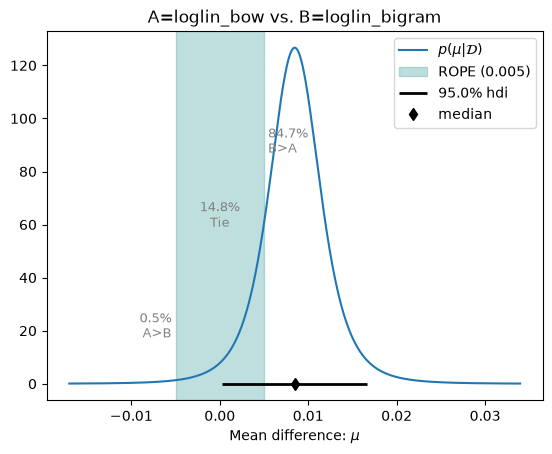

In [62]:
compare("loglin_bow", "loglin_bigram")

### 6.2 Architectures (on bag-of-bigrams)

Is the **MLP** better than the log-linear model, with the same representation?

A=loglin_bigram B=mlp_bigram: P(A wins)=0.0008 P(Tie)=0.0021 P(B wins)=0.9971 Effect Size=6.47


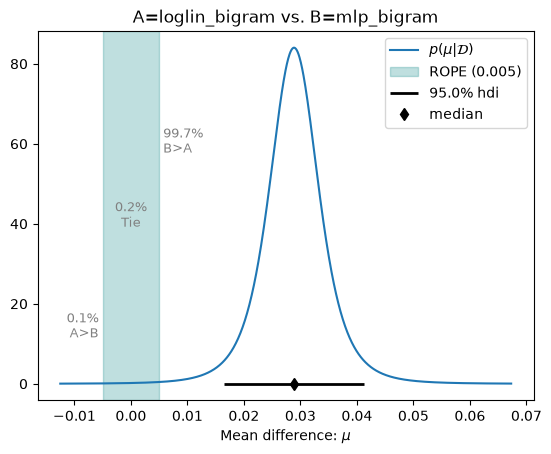

In [63]:
compare("loglin_bigram", "mlp_bigram")

### 6.3 Our own architecture vs the MLP

Does the **second hidden layer** help? (MLP vs our MLP with 2 hidden layers, both on bag-of-bigrams)

A=mlp_bigram B=own_mlp: P(A wins)=0.3705 P(Tie)=0.6257 P(B wins)=0.0038 Effect Size=-2.32


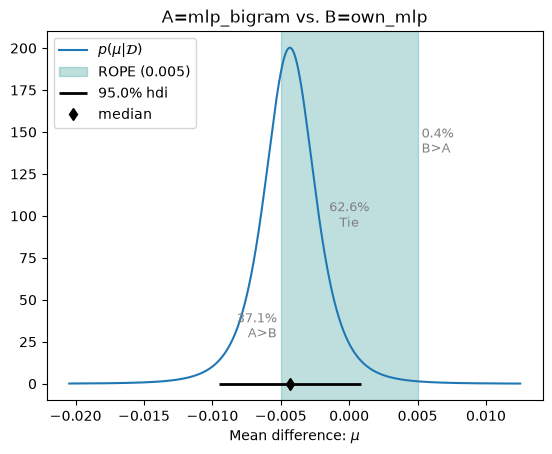

In [64]:
compare("mlp_bigram", "own_mlp")

### How much does the ROPE matter?

All comparisons in one table, with our ROPE (0.005) and a ROPE twice as big (0.01).

In [65]:
pairs = [
    ("loglin_indicator", "loglin_bow"),
    ("loglin_bow", "loglin_bigram"),
    ("loglin_bigram", "mlp_bigram"),
    ("mlp_bigram", "own_mlp"),
]

rows = []
for sys_a, sys_b in pairs:
    posterior = part1.analysis.BenavoliCorrelatedT(get_all_measurements_for(results, sys_a),
                                                   get_all_measurements_for(results, sys_b))
    for rope_size in [0.005, 0.01]:
        p_a, p_tie, p_b = posterior.probs(rope_size)
        rows.append({"A": sys_a, "B": sys_b, "ROPE": rope_size, "mean difference (B - A)": posterior.mean_diff,
                     "P(A wins)": p_a, "P(tie)": p_tie, "P(B wins)": p_b})

pd.DataFrame(rows).round(3)

,A,B,ROPE,mean difference (B - A),P(A wins),P(tie),P(B wins)
0,loglin_indicator,loglin_bow,0.005,0.005,0.001,0.436,0.562
1,loglin_indicator,loglin_bow,0.010,0.005,0.000,0.981,0.019
2,loglin_bow,loglin_bigram,0.005,0.008,0.005,0.148,0.847
3,loglin_bow,loglin_bigram,0.010,0.008,0.002,0.682,0.317
4,loglin_bigram,mlp_bigram,0.005,0.029,0.001,0.002,0.997
5,loglin_bigram,mlp_bigram,0.010,0.029,0.000,0.006,0.993
6,mlp_bigram,own_mlp,0.005,-0.004,0.371,0.626,0.004
7,mlp_bigram,own_mlp,0.010,-0.004,0.020,0.980,0.001


**What we see**

| Comparison (A vs B) | Mean difference | P(B wins), ROPE 0.005 | P(tie), ROPE 0.005 | P(tie), ROPE 0.01 |
|---|---|---|---|---|
| Token indicators vs bag-of-words | +0.5 points | 56% | 44% | 98% |
| Bag-of-words vs bag-of-bigrams | +0.9 points | 85% | 15% | 68% |
| Log-linear vs MLP (bigrams) | +2.9 points | **99.7%** | 0.2% | 0.6% |
| MLP vs our MLP with 2 hidden layers | −0.4 points | 0.4% | 63% | 98% |

- **The MLP is clearly better** than the log-linear model on the same bigrams: 99.7% probability, and that stays (99.3%) with a ROPE twice as big. The choice of architecture matters most.
- **Bigrams are probably better** than bag-of-words (85%). The gain is mostly between half a point and one point: with a ROPE of 0.01 it is mostly a tie (68%).
- **Counting vs marking is undecided.** The gain of 0.5 points is exactly at the edge of our ROPE (56% bag-of-words wins, 44% tie). With a ROPE of 0.01 it is almost certainly a tie (98%). In practice, counting barely matters.
- **A second hidden layer does not help.** Our own MLP is 0.4 points worse. With our ROPE it is most likely a tie (63%) or the one-layer MLP is better (37%); it is almost never better itself (0.4%). With a ROPE of 0.01 it is a tie (98%). So the simpler MLP is the better choice.
- **The ROPE only matters for the small differences** (the representations), not for the MLP.
- **A ROPE of 0.01 reinforces that gains are practically negligible, while the architectural advantage of the MLP remains robust** compared to a ROPE twice as small. As no evidence of improvement is observed, the one-layer MLP remains the preferred choice for this task.
- *Limitation:* we have 1 run of 5 folds, so the uncertainty is large. More seeds (e.g. `my_seeds = [0, 3, 5]`) would make it sharper, but cost about 3 times the training time.